# 04 · Modèle final et soumission

Le modèle final est la moyenne de **trois réglages CatBoost × trois graines**, entraînés sur les **105 000 lignes**. Score public : **0.92301**.

| Modèle | Paramètres (notebook 03) | Variables (notebook 02) |
|---|---|---|
| profondeur 6, jeu enrichi | profondeur 6, taux 0.03, L2 = 10, Bernoulli 0.8 | 72 colonnes |
| profondeur 8, jeu enrichi | profondeur 8, le reste identique | 72 colonnes |
| profondeur 6, jeu réduit | comme le premier | 68 colonnes |
| référence | comme le premier | variables de la série 1 (68 colonnes) |

Trois étapes : validation des modèles et de leur moyenne sur cinq plis, courbe d'apprentissage, réentraînement sur toutes les lignes. Pour tout refaire sans les résultats sauvegardés : exécuter 01, puis les sections 1 à 5 de 02, puis activer ici `cv_models`, `learning_curve` et `full_refit`.

Les cinq notebooks : 01 données → 02 variables → 03 choix des modèles → 04 modèle final → 05 analyse des erreurs. Les CSV sont dans `data/`, les résultats dans `artifacts/<nom du notebook>/`.

In [1]:
# Environnement, chemins et fonctions partagés par les cinq notebooks
from pathlib import Path
from datetime import datetime, timezone
import gc
import hashlib
import importlib
import importlib.metadata
import json
import os
import platform
import shutil
import subprocess
import sys
import time

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import Image, Markdown, display
from sklearn.metrics import brier_score_loss, log_loss, roc_auc_score
from sklearn.model_selection import StratifiedKFold, train_test_split

try:
    from google.colab import drive
    drive.mount('/content/drive')
    IN_COLAB = True
except ModuleNotFoundError:
    IN_COLAB = False


def find_project_dir():
    candidates = []
    if os.environ.get('HMDA_PROJECT_DIR'):
        candidates.append(Path(os.environ['HMDA_PROJECT_DIR']))
    here = Path.cwd().resolve()
    candidates += [here, *here.parents]
    candidates.append(Path('/content/drive/MyDrive/Colab Notebooks/demandes-de-pret-immobilier-aux-etats-unis'))
    for candidate in candidates:
        if (candidate / 'data' / 'train.csv').is_file() and (candidate / 'data' / 'test.csv').is_file():
            return candidate.expanduser().resolve()
    raise FileNotFoundError('Projet introuvable (data/train.csv et data/test.csv requis) ; définir HMDA_PROJECT_DIR')


PROJECT_DIR = find_project_dir()
DATA_DIR = PROJECT_DIR / 'data'                                        # CSV sources (lecture seule)
ARTIFACTS = PROJECT_DIR / 'artifacts'                                  # Résultats dans un sous-dossier par notebook
PREPARED_DIR = ARTIFACTS / '01_data_exploration'                       # 01 : données préparées et schéma fixe
FEATURE_DIR = ARTIFACTS / '02_feature_engineering' / 'feature_store'   # 02 : feature store
SEED = 42
CATBOOST_VERSION = '1.2.10'
GPU_NAME = None
plt.rcParams.update({'figure.dpi': 110, 'axes.grid': True, 'grid.alpha': 0.3})


def ensure_catboost():
    """Installe et importe la version fixée de CatBoost pour le réentraînement."""
    global catboost
    try:
        installed = importlib.metadata.version('catboost')
    except importlib.metadata.PackageNotFoundError:
        installed = None
    if installed != CATBOOST_VERSION:
        if 'catboost' in sys.modules:
            raise RuntimeError('Une autre version de CatBoost est déjà chargée ; redémarrer puis relancer le notebook')
        subprocess.check_call([sys.executable, '-m', 'pip', 'install', '-q', f'catboost=={CATBOOST_VERSION}'])
        importlib.invalidate_caches()
    import catboost as catboost_module
    if catboost_module.__version__ != CATBOOST_VERSION:
        raise RuntimeError(f'CatBoost {CATBOOST_VERSION} requis ; version chargée : {catboost_module.__version__}')
    catboost = catboost_module
    return catboost_module


def ensure_gpu():
    """Vérifie la présence du GPU NVIDIA avant le réentraînement."""
    global GPU_NAME
    if shutil.which('nvidia-smi') is None:
        raise RuntimeError('GPU requis : choisir un GPU T4 dans le type de session Colab, puis relancer')
    probe = subprocess.run(['nvidia-smi', '--query-gpu=name,memory.total', '--format=csv,noheader'],
                           text=True, capture_output=True, check=False)
    if probe.returncode != 0 or not probe.stdout.strip():
        raise RuntimeError('GPU NVIDIA indisponible : choisir un T4 puis relancer')
    GPU_NAME = probe.stdout.strip().splitlines()[0]
    return GPU_NAME


print('Projet :', PROJECT_DIR.name)
print(f'Python {platform.python_version()} | pandas {pd.__version__} | numpy {np.__version__}')

Projet : demandes-de-pret-immobilier-aux-etats-unis
Python 3.13.5 | pandas 2.2.3 | numpy 2.1.3


In [2]:
"""Identifiants de stockage historiques et libellés descriptifs.

Les valeurs assurent la reprise exacte des artefacts existants. Les paramètres,
les features et leur ordre sont définis dans les cellules métier.
Cette cellule est intégrée à chaque notebook : aucun import local requis.
"""

MODEL_DEPTH6_INITIAL = 'M0_C11_all'
MODEL_DEPTH6_ENRICHED = 'M1_C11_G7'
MODEL_DEPTH8_ENRICHED = 'M2_C7_G7'
MODEL_DEPTH6_REDUCED = 'M3_C11_lean'
FEATURE_SET_INITIAL = 'ROUND1_ALL'
FEATURE_SET_ENRICHED = 'G7'
FEATURE_SET_REDUCED = 'LEAN'
ENSEMBLE_THREE_MODELS_SEED42 = 'B13_seed42'
ENSEMBLE_MULTISEED = 'B_seeds'
ENSEMBLE_MULTISEED_PREFIX = 'B_seeds_'
ENSEMBLE_FULL_MULTISEED = 'full_Bseeds'
MODEL_INITIAL_POOL_LABEL = 'M0'
LEARNING_CURVE_SUBSET = 'LC_sub80'
LEARNING_CURVE_FULL = 'LC_full'
REDUCED_MODEL_CV_AUC = 'M3_in_13'
BASELINE_CATBOOST_DEPTH6 = 'CatBoost_R1'
BASELINE_CATBOOST_DEPTH8 = 'CatBoost_R2'
LIGHTGBM_LEAVES31 = 'L1_lgbm_leaves31'
LIGHTGBM_LEAVES127 = 'L2_lgbm_leaves127'
OBSERVED_LABELS_ONLY = 'A_base'
SOFT_PSEUDO_LABELS = 'A_pseudo'
LEARNING_CURVE_RUN_PATTERN = 'LC_*__fold?.json'
LEARNING_CURVE_FULL_PATTERN = 'LC_full__fold?.json'
REDUCED_MODEL_RUN_PATTERN = 'M3_C11_lean__fold?.json'
LIGHTGBM_RUN_PATTERN = 'L*_lgbm_*__fold?.json'
PSEUDO_LABEL_RUN_PATTERN = 'A_*__fold?.json'
FULL_ENSEMBLE_SUBMISSION = 'submission_full_Bseeds.csv'
ABLATION_ORIGINAL = 'F0_base'
ABLATION_ADD_DTI = 'F1_dti'
ABLATION_ADD_LTV = 'F2_ltv'
ABLATION_ADD_INCOME = 'F3_income'
ABLATION_ADD_MISSINGNESS = 'F4_missing'
ABLATION_ADD_GEOGRAPHIC_COUNTS = 'F5_freq'
ABLATION_INITIAL = 'F6_all'
ABLATION_INITIAL_REFERENCE = 'G0_all'
ABLATION_ADD_LTV_PRECISION = 'G1_precision'
ABLATION_ADD_LTV_THRESHOLDS = 'G2_thresholds'
ABLATION_ADD_IMPLIED_VALUE = 'G3_implied'
ABLATION_ADD_TERM = 'G4_term'
ABLATION_ENRICHED_WITH_COUNTS = 'G5_round2_all'
ABLATION_CORE_WITHOUT_COUNTS = 'G6_nofreq'
ABLATION_ENRICHED = 'G7_nofreq_round2_all'
ABLATION_ENRICHED_REFERENCE = 'H0_G7'
ABLATION_ADD_PRODUCT_FLAGS = 'H1_purpose'
ABLATION_ADD_LTV_CONSISTENCY = 'H2_ltv_consistency'
ABLATION_ADD_RISK_INTERACTIONS = 'H3_risk_layers'
ABLATION_ADD_TRACT_INCOME = 'H4_tract_income'
ABLATION_ALL_PRODUCT_RISK = 'H5_round3_all'
TUNING_DEPTH8_FIXED1600 = 'B0_R2_fixed1600'
TUNING_DEPTH8_LR005_L2_3 = 'C1_d8_lr05_l2_3_es'
TUNING_DEPTH6_LR003_L2_10 = 'C6_d6_lr03_l2_10'
TUNING_DEPTH8_LR003_L2_10 = 'C3_d8_lr03_l2_10'
TUNING_DEPTH8_LR003_L2_3 = 'C2_d8_lr03_l2_3'
TUNING_DEPTH8_LR003_L2_30 = 'C4_d8_lr03_l2_30'
TUNING_DEPTH8_BERNOULLI80 = 'C7_d8_lr03_l2_10_sub80'
TUNING_DEPTH8_WITH_DTI = 'C8_d8_lr03_l2_10_DTI'
TUNING_DEPTH10_LR003_L2_10 = 'C5_d10_lr03_l2_10'
TUNING_DEPTH8_LR002_L2_10 = 'C9_d8_lr02_l2_10'
TUNING_DEPTH8_L2_30_BERNOULLI80 = 'C10_d8_lr03_l2_30_sub80'
TUNING_DEPTH6_BERNOULLI80 = 'C11_d6_lr03_l2_10_sub80'
TRAINING_STANDARD = 'V0_base'
TRAINING_ORDERED = 'V1_ordered'
TRAINING_NEWTON_SCORE = 'V2_newtonL2'
TRAINING_DEPTHWISE = 'V3_depthwise'
TRAINING_LOSSGUIDE = 'V4_lossguide'
TRAINING_POISSON = 'V5_poisson'
TRAINING_ROWS066 = 'V6_sub066'
TRAINING_BINS254 = 'V7_border254'
TRAINING_NO_CATEGORY_COMBINATIONS = 'V8_ctr1'
TRAINING_DROP_REDUNDANT_DEMOGRAPHICS = 'V9_drop_demo'
MEAN_GAIN_VS_SOURCE_FEATURES = 'mean_delta_vs_F0'
FOLDS_BETTER_THAN_SOURCE_FEATURES = 'folds_better_than_F0'
MEAN_GAIN_VS_INITIAL_FEATURES = 'mean_delta_vs_G0'
FOLDS_BETTER_THAN_INITIAL_FEATURES = 'folds_better_than_G0'
MEAN_GAIN_VS_ENRICHED_FEATURES = 'mean_delta_vs_H0'
FOLDS_BETTER_THAN_ENRICHED_FEATURES = 'folds_better_than_H0'
MEAN_GAIN_VS_FIXED_ITERATIONS = 'mean_delta_vs_B0'
FOLDS_BETTER_THAN_FIXED_ITERATIONS = 'folds_better_than_B0'
MEAN_GAIN_VS_STANDARD_BOOSTING = 'mean_delta_vs_V0'
FOLDS_BETTER_THAN_STANDARD_BOOSTING = 'folds_better_than_V0'
GAIN_VS_THREE_MODEL_ENSEMBLE = 'delta_vs_B13'
FOLDS_BETTER_THAN_THREE_MODEL_ENSEMBLE = 'folds_better_than_B13'
TABM_ENSEMBLE_SUBMISSION_PREFIX = 'submission_Bseeds_TabM_w'
PURPOSE_ABLATION = 'feature block ablation, fast GPU CatBoost, paired vs F0_base'
PURPOSE_TRAINING_MODES = 'data-efficiency screen on M3 features; inner 15% early stop, score probe model on outer fold'
PURPOSE_TABM = 'TabM-mini (PyTorch) on G7 features; inner 15% early stop, no outer refit'
PURPOSE_FULL_REFIT = 'learning curve (80% vs 100% of outer-train) + full-data refit of M1-M3 x 3 seeds'

DISPLAY_LABELS = {
    MODEL_DEPTH6_INITIAL: 'CatBoost profondeur 6 · variables initiales',
    MODEL_DEPTH6_ENRICHED: 'CatBoost profondeur 6 · variables enrichies',
    MODEL_DEPTH8_ENRICHED: 'CatBoost profondeur 8 · variables enrichies',
    MODEL_DEPTH6_REDUCED: 'CatBoost profondeur 6 · variables réduites',
    FEATURE_SET_INITIAL: 'Variables initiales (68 colonnes)',
    FEATURE_SET_ENRICHED: 'Variables enrichies (72 colonnes)',
    FEATURE_SET_REDUCED: 'Variables réduites (68 colonnes)',
    ENSEMBLE_THREE_MODELS_SEED42: 'Ensemble de trois modèles · graine 42',
    ENSEMBLE_MULTISEED: 'Ensemble de trois modèles et trois graines',
    ENSEMBLE_MULTISEED_PREFIX: 'Ensemble multigraines · ',
    ENSEMBLE_FULL_MULTISEED: 'Ensemble multigraines sur toutes les données',
    MODEL_INITIAL_POOL_LABEL: 'CatBoost profondeur 6 · variables initiales',
    LEARNING_CURVE_SUBSET: 'Apprentissage sur 67 200 lignes',
    LEARNING_CURVE_FULL: 'Apprentissage sur 84 000 lignes',
    REDUCED_MODEL_CV_AUC: 'AUC du modèle réduit en validation croisée',
    BASELINE_CATBOOST_DEPTH6: 'CatBoost profondeur 6',
    BASELINE_CATBOOST_DEPTH8: 'CatBoost profondeur 8',
    LIGHTGBM_LEAVES31: 'LightGBM · 31 feuilles',
    LIGHTGBM_LEAVES127: 'LightGBM · 127 feuilles',
    OBSERVED_LABELS_ONLY: 'Cibles observées uniquement',
    SOFT_PSEUDO_LABELS: 'Pseudo-étiquettes souples',
    LEARNING_CURVE_RUN_PATTERN: 'Courbe d’apprentissage',
    LEARNING_CURVE_FULL_PATTERN: 'Courbe sur 84 000 lignes',
    REDUCED_MODEL_RUN_PATTERN: 'Validation croisée du modèle réduit',
    LIGHTGBM_RUN_PATTERN: 'Modèles LightGBM',
    PSEUDO_LABEL_RUN_PATTERN: 'Comparaison des pseudo-étiquettes',
    FULL_ENSEMBLE_SUBMISSION: 'Soumission de l’ensemble complet',
    ABLATION_ORIGINAL: 'Variables sources',
    ABLATION_ADD_DTI: 'Ajout des bornes DTI',
    ABLATION_ADD_LTV: 'Ajout de la cohérence LTV',
    ABLATION_ADD_INCOME: 'Ajout des ratios de revenu',
    ABLATION_ADD_MISSINGNESS: 'Ajout des valeurs manquantes',
    ABLATION_ADD_GEOGRAPHIC_COUNTS: 'Ajout des fréquences géographiques',
    ABLATION_INITIAL: 'Toutes les variables initiales',
    ABLATION_INITIAL_REFERENCE: 'Référence : variables initiales',
    ABLATION_ADD_LTV_PRECISION: 'Ajout de la précision LTV',
    ABLATION_ADD_LTV_THRESHOLDS: 'Ajout des seuils LTV',
    ABLATION_ADD_IMPLIED_VALUE: 'Ajout de la valeur immobilière implicite',
    ABLATION_ADD_TERM: 'Ajout des variables de durée',
    ABLATION_ENRICHED_WITH_COUNTS: 'Variables enrichies avec fréquences géographiques',
    ABLATION_CORE_WITHOUT_COUNTS: 'Variables initiales sans fréquences géographiques',
    ABLATION_ENRICHED: 'Variables enrichies sans fréquences géographiques',
    ABLATION_ENRICHED_REFERENCE: 'Référence : variables enrichies',
    ABLATION_ADD_PRODUCT_FLAGS: 'Ajout des indicateurs de produit',
    ABLATION_ADD_LTV_CONSISTENCY: 'Ajout de la cohérence des intervalles LTV',
    ABLATION_ADD_RISK_INTERACTIONS: 'Ajout des interactions de risque',
    ABLATION_ADD_TRACT_INCOME: 'Ajout du revenu relatif au secteur',
    ABLATION_ALL_PRODUCT_RISK: 'Ajout de tous les blocs produit et risque',
    TUNING_DEPTH8_FIXED1600: 'Profondeur 8 · 1 600 itérations fixes',
    TUNING_DEPTH8_LR005_L2_3: 'Profondeur 8 · taux 0.05 · L2=3',
    TUNING_DEPTH6_LR003_L2_10: 'Profondeur 6 · taux 0.03 · L2=10',
    TUNING_DEPTH8_LR003_L2_10: 'Profondeur 8 · taux 0.03 · L2=10',
    TUNING_DEPTH8_LR003_L2_3: 'Profondeur 8 · taux 0.03 · L2=3',
    TUNING_DEPTH8_LR003_L2_30: 'Profondeur 8 · taux 0.03 · L2=30',
    TUNING_DEPTH8_BERNOULLI80: 'Profondeur 8 · taux 0.03 · L2=10 · Bernoulli 0.8',
    TUNING_DEPTH8_WITH_DTI: 'Profondeur 8 · taux 0.03 · L2=10 · bornes DTI',
    TUNING_DEPTH10_LR003_L2_10: 'Profondeur 10 · taux 0.03 · L2=10',
    TUNING_DEPTH8_LR002_L2_10: 'Profondeur 8 · taux 0.02 · L2=10',
    TUNING_DEPTH8_L2_30_BERNOULLI80: 'Profondeur 8 · taux 0.03 · L2=30 · Bernoulli 0.8',
    TUNING_DEPTH6_BERNOULLI80: 'Profondeur 6 · taux 0.03 · L2=10 · Bernoulli 0.8',
    TRAINING_STANDARD: 'Boosting standard',
    TRAINING_ORDERED: 'Boosting ordonné',
    TRAINING_NEWTON_SCORE: 'Score NewtonL2',
    TRAINING_DEPTHWISE: 'Croissance par profondeur',
    TRAINING_LOSSGUIDE: 'Croissance guidée par la perte',
    TRAINING_POISSON: 'Échantillonnage Poisson',
    TRAINING_ROWS066: 'Échantillonnage des lignes à 0.66',
    TRAINING_BINS254: '254 seuils numériques',
    TRAINING_NO_CATEGORY_COMBINATIONS: 'Sans combinaison de catégories',
    TRAINING_DROP_REDUNDANT_DEMOGRAPHICS: 'Sans colonnes démographiques redondantes',
    MEAN_GAIN_VS_SOURCE_FEATURES: 'Gain moyen face à la référence',
    FOLDS_BETTER_THAN_SOURCE_FEATURES: 'Plis meilleurs que la référence',
    MEAN_GAIN_VS_INITIAL_FEATURES: 'Gain moyen face à la référence',
    FOLDS_BETTER_THAN_INITIAL_FEATURES: 'Plis meilleurs que la référence',
    MEAN_GAIN_VS_ENRICHED_FEATURES: 'Gain moyen face à la référence',
    FOLDS_BETTER_THAN_ENRICHED_FEATURES: 'Plis meilleurs que la référence',
    MEAN_GAIN_VS_FIXED_ITERATIONS: 'Gain moyen face à la référence',
    FOLDS_BETTER_THAN_FIXED_ITERATIONS: 'Plis meilleurs que la référence',
    MEAN_GAIN_VS_STANDARD_BOOSTING: 'Gain moyen face à la référence',
    FOLDS_BETTER_THAN_STANDARD_BOOSTING: 'Plis meilleurs que la référence',
    GAIN_VS_THREE_MODEL_ENSEMBLE: 'Gain face à l’ensemble de trois modèles',
    FOLDS_BETTER_THAN_THREE_MODEL_ENSEMBLE: 'Plis meilleurs que l’ensemble de trois modèles',
    TABM_ENSEMBLE_SUBMISSION_PREFIX: 'submission_Bseeds_TabM_w',
}

def semantic_label(value):
    """Décrit un identifiant historique pour l’affichage uniquement."""
    if not isinstance(value, str):
        return value
    # Un chemin affiché doit continuer à désigner le fichier réellement présent.
    if value.endswith(('.csv', '.json', '.parquet', '.npy')):
        return value
    if value in DISPLAY_LABELS:
        return DISPLAY_LABELS[value]
    for stored in sorted(DISPLAY_LABELS, key=len, reverse=True):
        value = value.replace(stored, DISPLAY_LABELS[stored])
    return value


def display_named(value, *args, **kwargs):
    """Affiche une copie : index, colonnes et libellés lisibles, calculs inchangés."""
    if isinstance(value, (pd.DataFrame, pd.Series)):
        value = value.copy(deep=True)
        if not isinstance(value.index, pd.MultiIndex):
            value.index = value.index.map(semantic_label)
        if isinstance(value, pd.DataFrame):
            value.columns = value.columns.map(semantic_label)
            for column in value.select_dtypes(include=['object', 'string']).columns:
                value[column] = value[column].map(semantic_label)
        elif value.dtype == object:
            value = value.map(semantic_label)
    display(value, *args, **kwargs)

**Entraînement.** Tous les boutons de `TRAIN` sont à `False` : les notebooks relisent les résultats sauvegardés dans `artifacts/`. Deux exceptions : le notebook 01 entraîne un petit modèle de contrôle sur CPU et le notebook 02 réécrit les variables. Pour refaire une expérience, mettre son bouton à `True` et choisir un **GPU T4** si le bloc le demande. Les modèles déjà entraînés sont sauvegardés et ne sont pas refaits.

In [3]:
TRAIN = {
    'cv_models': False,        # la référence initiale et les trois modèles finaux × 3 seeds, cinq folds (GPU, environ 6 h)
    'learning_curve': False,   # Courbe d’apprentissage : 10 entraînements (GPU, environ 75 min)
    'full_refit': False,       # Réentraînement complet : 9 modèles (GPU, environ 50 min)
}

## 0. Chargement des données et des variables

In [4]:
def require(condition, message):
    if not bool(condition):
        raise ValueError(message)


def sha256_file(path):
    digest = hashlib.sha256()
    with Path(path).open('rb') as handle:
        for chunk in iter(lambda: handle.read(1024 * 1024), b''):
            digest.update(chunk)
    return digest.hexdigest()


manifest_path = PREPARED_DIR / 'manifest.json'
schema_path = PREPARED_DIR / 'schema.json'
if not manifest_path.is_file() or not schema_path.is_file():
    raise FileNotFoundError(
        f'Fichier manquant : {manifest_path} ou {schema_path} ; exécuter d’abord 01_data_exploration.ipynb'
    )
manifest = json.loads(manifest_path.read_text(encoding='utf-8'))
schema = json.loads(schema_path.read_text(encoding='utf-8'))
require(manifest['schema_version'] == schema['schema_version'] == '1.0', 'Version du contrat de données incompatible')
require(manifest['seed'] == SEED and manifest['n_splits'] == 5, 'Configuration des cinq folds incompatible')
require(set(manifest['source_files']) == {'train.csv', 'test.csv', 'sample_submission.csv'},
        'Liste des fichiers source incomplète')
expected_prepared = {
    'train_features.csv', 'test_features.csv', 'train_labels.csv',
    'test_ids.csv', 'folds.csv', 'audit.csv', 'schema.json',
}
require(set(manifest['output_files']) == expected_prepared, 'Liste des fichiers préparés incomplète')
for name, info in manifest['source_files'].items():
    path = DATA_DIR / name
    require(path.is_file(), f'Données source manquantes : {path}')
    require(sha256_file(path) == info['sha256'], f'Fichier source modifié : {name} ; réexécuter 01')
for name, info in manifest['output_files'].items():
    path = PREPARED_DIR / name
    require(path.is_file(), f'Fichier préparé manquant : {path}')
    require(sha256_file(path) == info['sha256'], f'Empreinte du fichier préparé différente : {name} ; réexécuter 01')

FEATURE_COLUMNS = schema['feature_columns']
NUMERIC_COLUMNS = schema['numeric_columns']
CATEGORICAL_COLUMNS = schema['categorical_columns']
require(len(FEATURE_COLUMNS) == 56 and len(NUMERIC_COLUMNS) == 13
        and len(CATEGORICAL_COLUMNS) == 43, '56 colonnes attendues : 13 numériques, 43 catégorielles')
require(set(FEATURE_COLUMNS) == set(NUMERIC_COLUMNS + CATEGORICAL_COLUMNS),
        'Répartition numérique/catégorielle incomplète')
require(not {'id', 'accepted'} & set(FEATURE_COLUMNS), 'Les ID et la cible ne peuvent pas servir de variables')


def read_features(path):
    frame = pd.read_csv(path, dtype=str, keep_default_na=False)
    require(frame.columns.tolist() == FEATURE_COLUMNS, f'Variables ou ordre des colonnes incompatibles : {path.name}')
    for column in NUMERIC_COLUMNS:
        frame[column] = pd.to_numeric(
            frame[column].replace('', np.nan), errors='raise',
        ).astype('float64')
    require(not np.isinf(frame[NUMERIC_COLUMNS].to_numpy()).any(), 'Valeurs infinies dans les colonnes numériques')
    require(not frame[CATEGORICAL_COLUMNS].eq('').any().any(), 'Chaînes vides dans les colonnes catégorielles')
    return frame


X_base = read_features(PREPARED_DIR / 'train_features.csv')
X_test_base = read_features(PREPARED_DIR / 'test_features.csv')
labels = pd.read_csv(PREPARED_DIR / 'train_labels.csv', dtype=str, keep_default_na=False)
test_id_frame = pd.read_csv(PREPARED_DIR / 'test_ids.csv', dtype=str, keep_default_na=False)
fold_frame = pd.read_csv(PREPARED_DIR / 'folds.csv', dtype=str, keep_default_na=False)
sample_submission = pd.read_csv(DATA_DIR / 'sample_submission.csv', dtype=str, keep_default_na=False)

require(labels.columns.tolist() == ['id', 'accepted'], 'Colonnes des cibles train incompatibles')
require(test_id_frame.columns.tolist() == ['id'], 'Colonnes des ID test incompatibles')
require(fold_frame.columns.tolist() == ['id', 'fold'], 'Colonnes du fichier de folds incompatibles')
require(sample_submission.columns.tolist() == ['id', 'accepted'], 'Colonnes du modèle de soumission incompatibles')
require(len(X_base) == len(labels) == len(fold_frame) == 105000, 'Nombre de lignes train incorrect')
require(len(X_test_base) == len(test_id_frame) == len(sample_submission) == 45000,
        'Nombre de lignes test incorrect')

train_ids = labels['id']
test_ids = test_id_frame['id']
require(train_ids.is_unique and test_ids.is_unique, 'ID en double')
require(train_ids.ne('').all() and test_ids.ne('').all(), 'ID vide')
require(train_ids.equals(fold_frame['id']), 'ID des folds désalignés avec le train')
require(test_ids.equals(sample_submission['id']), 'Ordre des ID test différent du modèle de soumission')
require(set(train_ids).isdisjoint(test_ids), 'ID communs au train et au test')
require(set(labels['accepted']) == {'0', '1'}, 'accepted doit contenir les deux valeurs 0 et 1')
raw_train_identity = pd.read_csv(
    DATA_DIR / 'train.csv', usecols=['id', 'accepted'],
    dtype=str, keep_default_na=False,
)
raw_test_identity = pd.read_csv(
    DATA_DIR / 'test.csv', usecols=['id'], dtype=str, keep_default_na=False,
)
require(train_ids.equals(raw_train_identity['id'])
        and labels['accepted'].equals(raw_train_identity['accepted']),
        'ID ou cibles préparés différents du train.csv initial')
require(test_ids.equals(raw_test_identity['id']),
        'ID test préparés différents du test.csv initial')
y = labels['accepted'].astype('int8')
require(set(fold_frame['fold']) == {'1', '2', '3', '4', '5'}, 'Les folds doivent être numérotés de 1 à 5')
fold_assignment = fold_frame['fold'].astype('int8').to_numpy()

expected_folds = np.zeros(len(X_base), dtype=np.int8)
splitter = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)
for fold, (_, valid_index) in enumerate(splitter.split(X_base, y), start=1):
    expected_folds[valid_index] = fold
require(np.array_equal(fold_assignment, expected_folds), 'Les folds ne correspondent pas au découpage fixe avec seed=42')
DATA_HASHES = {
    'manifest.json': sha256_file(manifest_path),
    **{name: info['sha256'] for name, info in manifest['output_files'].items()},
}
print(f'Données vérifiées : train {len(X_base):,}, test {len(X_test_base):,}, 56 variables initiales.')
display_named(pd.crosstab(fold_assignment, y, rownames=['fold'], colnames=['accepted']))

def checked_probabilities(model, features):
    require(list(model.classes_) == [0, 1], 'Ordre des classes différent de [0, 1]')
    probability = np.asarray(model.predict_proba(features)[:, 1], dtype=float)
    require(probability.ndim == 1 and len(probability) == len(features)
            and np.isfinite(probability).all()
            and ((probability >= 0) & (probability <= 1)).all(),
            'Probabilités prédites invalides')
    return probability


def write_json(path, payload):
    tmp = path.with_suffix(path.suffix + '.tmp')
    tmp.write_text(json.dumps(payload, ensure_ascii=False, indent=2), encoding='utf-8')
    tmp.replace(path)


def fixed_config(output_dir, config):
    """Écrire la configuration au premier passage, puis exiger son identité pour ne pas mélanger les expériences."""
    output_dir.mkdir(parents=True, exist_ok=True)
    path = output_dir / 'config.json'
    if path.is_file():
        saved = json.loads(path.read_text(encoding='utf-8'))
        require(saved == config,
                f'{output_dir.name} contient des résultats avec une autre configuration ; changer EXPERIMENT_ID')
    else:
        write_json(path, config)

Données vérifiées : train 105,000, test 45,000, 56 variables initiales.


accepted,0,1
fold,,
1,3151,17849
2,3151,17849
3,3151,17849
4,3151,17849
5,3152,17848


In [5]:
# Charge les features produites par 02, nécessaires au réentraînement.
def load_feature_store():
    meta_path = FEATURE_DIR / 'feature_store.json'
    require(meta_path.is_file(), 'Feature store absent : exécuter 02_feature_engineering.ipynb')
    meta = json.loads(meta_path.read_text(encoding='utf-8'))
    require(meta['data_hashes'] == DATA_HASHES, 'Feature store incompatible avec les données de 01 : relancer 02')
    stores = {}
    for part, expected_rows in [('train', len(X_base)), ('test', len(X_test_base))]:
        path = FEATURE_DIR / f'blocks_{part}.parquet'
        require(sha256_file(path) == meta['files'][path.name], f'SHA-256 incorrect pour {path.name} : relancer 02')
        frame = pd.read_parquet(path)
        require(len(frame) == expected_rows, f'Nombre de lignes incorrect : {path.name}')
        for column in frame.columns:
            frame[column] = frame[column].astype(object if column in meta['categorical'] else 'float64')
        stores[part] = frame
    blocks = {name: (stores['train'][cols].reset_index(drop=True), stores['test'][cols].reset_index(drop=True))
              for name, cols in meta['blocks'].items()}
    return blocks, set(meta['categorical']), meta


def variant_frames(blocks):
    """Ajoute les blocs choisis aux 56 colonnes sources, comme dans 02."""
    train_parts = [X_base] + [BLOCKS[b][0] for b in blocks]
    test_parts = [X_test_base] + [BLOCKS[b][1] for b in blocks]
    train = pd.concat(train_parts, axis=1)
    test = pd.concat(test_parts, axis=1)
    require(train.columns.is_unique and train.columns.equals(test.columns), 'Colonnes incohérentes entre les variantes train/test')
    require(train.iloc[:, :len(FEATURE_COLUMNS)].equals(X_base), 'Les 56 colonnes sources ont été modifiées')
    cats = CATEGORICAL_COLUMNS + [c for c in train.columns if c in NEW_CATEGORICAL]
    return train, test, cats


if (FEATURE_DIR / 'feature_store.json').is_file():
    BLOCKS, NEW_CATEGORICAL, FEATURE_META = load_feature_store()
    print(f"Feature store : {len(BLOCKS)} blocs, {sum(len(c) for c in FEATURE_META['blocks'].values())} colonnes ; "
          f"jeux de features {[semantic_label(name) for name in FEATURE_META['feature_sets']]}")
else:
    BLOCKS, NEW_CATEGORICAL, FEATURE_META = None, set(), None
    print('Feature store absent : lecture des résultats possible ; exécuter 02 avant le réentraînement.')

Feature store : 13 blocs, 25 colonnes ; jeux de features ['Variables initiales (68 colonnes)', 'Variables enrichies (72 colonnes)', 'Variables réduites (68 colonnes)']


In [6]:
# Lit les résultats JSON par modèle et fold pour des comparaisons appariées.
def load_runs(directory, pattern='*__fold?.json'):
    directory = Path(directory)
    paths = sorted(directory.glob(pattern))
    require(paths, f'Aucun résultat dans {directory} : synchroniser artifacts depuis Drive ou activer le réentraînement')
    return pd.DataFrame([json.loads(p.read_text(encoding='utf-8')) for p in paths])


def paired_table(runs, key, baseline, min_gain=0.0005, min_folds=4):
    auc = runs.pivot(index='fold', columns=key, values='valid_auc')
    require(baseline in auc.columns, f'Référence absente : {baseline}')
    delta = auc.sub(auc[baseline], axis=0)
    table = pd.DataFrame({
        'folds': auc.notna().sum(),
        'mean_auc': auc.mean(),
        'delta_vs_base': delta.mean(),
        'folds_better': (delta > 0).sum(),
    })
    table['keep'] = ((table['folds'] == 5) & (table['delta_vs_base'] >= min_gain)
                     & (table['folds_better'] >= min_folds))
    table.loc[baseline, 'keep'] = False
    return table.sort_values('mean_auc', ascending=False), delta


def plot_deltas(delta, baseline, title):
    others = delta.drop(columns=[baseline])
    order = others.mean().sort_values().index.tolist()
    means = others[order].mean() * 1e4
    fig, ax = plt.subplots(figsize=(8, 0.45 * len(order) + 1.6))
    ax.barh(range(len(order)), means, color=['#4c72b0' if v > 0 else '#c44e52' for v in means])
    for i, name in enumerate(order):
        ax.scatter(others[name] * 1e4, np.full(len(others), i), color='black', s=12, zorder=3)
    ax.axvline(0, color='black', lw=0.8)
    ax.set_yticks(range(len(order)), [semantic_label(name) for name in order])
    ax.set_xlabel(f'Écart AUC / {semantic_label(baseline)} (×1e-4) ; barre = moyenne, points = folds')
    ax.set_title(title)
    plt.tight_layout()
    plt.show()



# Lit les prédictions OOF des cinq folds externes.
def read_oof(directory, group):
    frames = [pd.read_csv(Path(directory) / f'{group}__fold{k}__valid.csv').assign(fold=k) for k in range(1, 6)]
    return pd.concat(frames).sort_values('id', kind='stable').reset_index(drop=True)


def fold_auc(frame, probability):
    probability = np.asarray(probability)
    return pd.Series({k: roc_auc_score(frame.loc[frame['fold'].eq(k), 'accepted'],
                                       probability[frame['fold'].eq(k).to_numpy()]) for k in range(1, 6)})


def mean_test(paths):
    frames = [pd.read_csv(p, dtype={'id': str}) for p in paths]
    for f in frames:
        require(f['id'].equals(sample_submission['id']), f'Ordre des ID de test incohérent : {Path(paths[0]).name}')
    return np.mean([f['accepted'].to_numpy() for f in frames], axis=0)


CV_DIR = ARTIFACTS / '04_final_model' / 'cv_models'      # Modèles sur cinq folds (la référence initiale et les trois modèles finaux × 3 seeds)
FULL_DIR = ARTIFACTS / '04_final_model' / 'full_refit'   # Courbe d’apprentissage et modèles sur toutes les données
FINAL_MODEL_NAMES = [MODEL_DEPTH6_ENRICHED, MODEL_DEPTH8_ENRICHED, MODEL_DEPTH6_REDUCED]
SEED_TAGS = {42: '', 2027: '_s2027', 31415: '_s31415'}

## 1. Modèles sur cinq plis et moyenne

Même protocole que dans le notebook 03 : early stopping sur 15 % de la partie d'apprentissage, puis réentraînement pendant `round(b / 0.85)` itérations. Chaque modèle prédit aussi le test. Les trois modèles finaux sont entraînés avec les graines 42, 2027 et 31415.

In [7]:
EXPERIMENT_ID = 'cv_models'
FOLDS = [1, 2, 3, 4, 5]
RUN_ONLY = None             # None entraîne les groupes manquants ; ceux déjà terminés sont ignorés
INNER_STOP_FRACTION = 0.15
MAX_ITERATIONS = 10000
OD_WAIT = 300
OUTPUT_DIR = ARTIFACTS / '04_final_model' / EXPERIMENT_ID

GPU_BASE = dict(
    loss_function='Logloss', nan_mode='Min', random_seed=SEED,
    task_type='GPU', devices='0', thread_count=4,
    allow_writing_files=False, verbose=False,
)
INITIAL_FEATURE_BLOCKS = ['dti', 'ltv', 'income', 'missing', 'freq']
CORE_FEATURE_BLOCKS = ['dti', 'ltv', 'income', 'missing']
FAST_SCREEN_PARAMS = dict(depth=8, learning_rate=0.05, l2_leaf_reg=3,
            bootstrap_type='Bernoulli', subsample=0.8, early_stop=False, iterations=1600)
CATBOOST_DEPTH8_PARAMS = dict(depth=8, learning_rate=0.03, l2_leaf_reg=10, bootstrap_type='Bernoulli', subsample=0.8)
CATBOOST_DEPTH6_PARAMS = dict(depth=6, learning_rate=0.03, l2_leaf_reg=10, bootstrap_type='Bernoulli', subsample=0.8)
LTV_DETAIL_BLOCKS = ['precision', 'thresholds', 'implied', 'term']
ENRICHED_FEATURE_BLOCKS = CORE_FEATURE_BLOCKS + LTV_DETAIL_BLOCKS                      # Meilleur jeu de variables du notebook 02 (72 colonnes)
REDUCED_FEATURE_BLOCKS = CORE_FEATURE_BLOCKS + ['precision', 'thresholds']  # Deux blocs de la deuxième série utiles isolément (68 colonnes)
GROUPS = {
    MODEL_DEPTH6_INITIAL: dict(params=CATBOOST_DEPTH6_PARAMS, blocks=INITIAL_FEATURE_BLOCKS),   # Toutes les variables de la première série ; référence comparable (score public 0.92073)
    MODEL_DEPTH6_ENRICHED: dict(params=CATBOOST_DEPTH6_PARAMS, blocks=ENRICHED_FEATURE_BLOCKS),
    MODEL_DEPTH8_ENRICHED: dict(params=CATBOOST_DEPTH8_PARAMS, blocks=ENRICHED_FEATURE_BLOCKS),
    MODEL_DEPTH6_REDUCED: dict(params=CATBOOST_DEPTH6_PARAMS, blocks=REDUCED_FEATURE_BLOCKS),
}
BASELINE = MODEL_DEPTH6_INITIAL
FINAL_MODEL_NAMES = [MODEL_DEPTH6_ENRICHED, MODEL_DEPTH8_ENRICHED, MODEL_DEPTH6_REDUCED]
SEEDS_EXTRA = [2027, 31415]          # Deux seeds supplémentaires ; seed 42 pour les groupes de base
for base_name in FINAL_MODEL_NAMES:
    for extra_seed in SEEDS_EXTRA:
        base_group = GROUPS[base_name]
        GROUPS[f'{base_name}_s{extra_seed}'] = dict(
            params=dict(base_group['params'], random_seed=extra_seed), blocks=base_group['blocks'])

if RUN_ONLY is not None:
    unknown = set(RUN_ONLY) - set(GROUPS)
    if unknown:
        raise ValueError(f'Groupes inconnus dans RUN_ONLY : {sorted(unknown)}')

In [8]:
if TRAIN['cv_models']:
    ensure_catboost()
    ensure_gpu()
    fixed_config(OUTPUT_DIR, {
        'purpose': 'params x feature blocks, 5-fold with inner early stop; fold-averaged test predictions',
        'seed': SEED, 'inner_stop_fraction': INNER_STOP_FRACTION,
        'max_iterations': MAX_ITERATIONS, 'od_wait': OD_WAIT,
        'gpu_base': {k: v for k, v in GPU_BASE.items() if k != 'thread_count'},
        'data_hashes': DATA_HASHES,
    })


    def model_params(spec, iterations):
        params = {k: v for k, v in spec.items() if k not in {'early_stop', 'iterations'}}
        return dict(GPU_BASE, **params, iterations=iterations)


    def run_one(name, group, fold):
        spec = group['params']
        train, test, cats = variant_frames(group['blocks'])
        fit_idx = np.flatnonzero(fold_assignment != fold)
        valid_idx = np.flatnonzero(fold_assignment == fold)
        started = time.perf_counter()
        best_iteration, early_stopped = None, None
        if spec.get('early_stop', True):
            inner_fit, inner_stop = train_test_split(
                fit_idx, test_size=INNER_STOP_FRACTION, random_state=SEED,
                stratify=y.iloc[fit_idx],
            )
            probe = catboost.CatBoostClassifier(**model_params(spec, MAX_ITERATIONS),
                                                eval_metric='Logloss', od_type='Iter',
                                                od_wait=OD_WAIT, use_best_model=True)
            probe.fit(train.iloc[inner_fit], y.iloc[inner_fit], cat_features=cats,
                      eval_set=(train.iloc[inner_stop], y.iloc[inner_stop]))
            best_iteration = int(probe.get_best_iteration()) + 1
            early_stopped = int(probe.tree_count_) < MAX_ITERATIONS
            if not early_stopped:
                print(f'  Attention : {name} atteint {MAX_ITERATIONS} itérations sans arrêt anticipé')
            rounds = int(round(best_iteration / (1 - INNER_STOP_FRACTION)))
            del probe
            gc.collect()
        else:
            rounds = int(spec['iterations'])
        model = catboost.CatBoostClassifier(**model_params(spec, rounds), use_best_model=False)
        model.fit(train.iloc[fit_idx], y.iloc[fit_idx], cat_features=cats)
        require(int(model.tree_count_) == rounds, 'Nombre d’itérations incorrect pour le réentraînement externe')
        valid_prob = checked_probabilities(model, train.iloc[valid_idx])
        test_prob = checked_probabilities(model, test)
        actual = y.iloc[valid_idx]
        stem = OUTPUT_DIR / f'{name}__fold{fold}'
        pd.DataFrame({'id': train_ids.iloc[valid_idx].to_numpy(), 'accepted': actual.to_numpy(),
                      'prob': valid_prob}).to_csv(f'{stem}__valid.csv', index=False, float_format='%.12f')
        pd.DataFrame({'id': test_ids.to_numpy(), 'accepted': test_prob}).to_csv(
            f'{stem}__test.csv', index=False, float_format='%.12f')
        result = {
            'group': name, 'fold': fold, 'definition': group,
            'feature_count': train.shape[1],
            'inner_best_iteration': best_iteration, 'early_stopped': early_stopped,
            'refit_rounds': rounds,
            'valid_auc': roc_auc_score(actual, valid_prob),
            'valid_logloss': log_loss(actual, valid_prob, labels=[0, 1]),
            'seconds': time.perf_counter() - started, 'gpu_name': GPU_NAME,
            'finished_at_utc': datetime.now(timezone.utc).isoformat(),
        }
        write_json(Path(f'{stem}.json'), result)   # Écrire le JSON en dernier : il marque la fin du fold
        del model, train, test
        gc.collect()
        return result


    selected = {n: g for n, g in GROUPS.items() if RUN_ONLY is None or n in RUN_ONLY}
    for fold in FOLDS:
        for name, group in selected.items():
            result_path = OUTPUT_DIR / f'{name}__fold{fold}.json'
            if result_path.is_file():
                saved = json.loads(result_path.read_text(encoding='utf-8'))
                require(saved['definition'] == group, f'{name} : définition modifiée ; renommer le groupe')
                print(f'{name} fold {fold}: terminé, AUC={saved["valid_auc"]:.6f}, ignoré')
                continue
            result = run_one(name, group, fold)
            print(f'{name} fold {fold}: AUC={result["valid_auc"]:.6f}  '
                  f'itérations={result["refit_rounds"]}  {result["seconds"]/60:.1f} min', flush=True)

    results = pd.DataFrame([json.loads(p.read_text(encoding='utf-8'))
                            for p in sorted(OUTPUT_DIR.glob('*__fold?.json'))])
    done = {g for g, part in results.groupby('group') if sorted(part['fold']) == [1, 2, 3, 4, 5]}
    print('Groupes ayant terminé les cinq folds :', sorted(done))


    def load(name):
        valid = pd.concat([pd.read_csv(OUTPUT_DIR / f'{name}__fold{k}__valid.csv').assign(fold=k)
                           for k in range(1, 6)]).sort_values('id', kind='stable').reset_index(drop=True)
        tests = [pd.read_csv(OUTPUT_DIR / f'{name}__fold{k}__test.csv', dtype={'id': str}) for k in range(1, 6)]
        for frame in tests:
            require(frame['id'].equals(sample_submission['id']), f'{name} : ordre des ID test incohérent')
        return valid, np.mean([t['accepted'].to_numpy() for t in tests], axis=0)


    loaded = {name: load(name) for name in sorted(done)}
    reference = loaded[FINAL_MODEL_NAMES[0]][0][['id', 'accepted', 'fold']]
    for name, (valid, _) in loaded.items():
        require(valid['id'].equals(reference['id']), f'{name} : ID OOF différents de la référence')


    def mean_of(names):
        return (np.mean([loaded[n][0]['prob'].to_numpy() for n in names], axis=0),
                np.mean([loaded[n][1] for n in names], axis=0))


    def fold_aucs(probability):
        return pd.Series({k: roc_auc_score(reference.loc[reference['fold'].eq(k), 'accepted'],
                                           probability[reference['fold'].eq(k).to_numpy()])
                          for k in range(1, 6)})


    blends = {}
    require(all(b in done for b in FINAL_MODEL_NAMES), 'Résultats sur cinq folds manquants pour les trois modèles finaux')
    blends[ENSEMBLE_THREE_MODELS_SEED42] = mean_of(FINAL_MODEL_NAMES)                       # = soumission ayant obtenu 0.92190
    per_base = [mean_of([b] + [f'{b}_s{s}' for s in SEEDS_EXTRA if f'{b}_s{s}' in done]) for b in FINAL_MODEL_NAMES]
    n_seeds = {b: 1 + sum(f'{b}_s{s}' in done for s in SEEDS_EXTRA) for b in FINAL_MODEL_NAMES}
    seed_tag = ENSEMBLE_MULTISEED_PREFIX + '_'.join(str(n_seeds[b]) for b in FINAL_MODEL_NAMES)
    blends[seed_tag] = (np.mean([v for v, _ in per_base], axis=0), np.mean([t for _, t in per_base], axis=0))

    ref_folds = fold_aucs(blends[ENSEMBLE_THREE_MODELS_SEED42][0])
    rows = []
    for name, (valid_prob, test_prob) in blends.items():
        folds = fold_aucs(valid_prob)
        require(np.isfinite(test_prob).all() and len(test_prob) == 45000, f'{name} : probabilités test invalides')
        path = OUTPUT_DIR / f'submission_{name}.csv'
        pd.DataFrame({'id': sample_submission['id'], 'accepted': test_prob}).to_csv(
            path, index=False, float_format='%.12f')
        rows.append({'blend': name, 'mean_auc': folds.mean(),
                     GAIN_VS_THREE_MODEL_ENSEMBLE: (folds - ref_folds).mean(),
                     FOLDS_BETTER_THAN_THREE_MODEL_ENSEMBLE: int(((folds - ref_folds) > 0).sum()),
                     'oof_auc': roc_auc_score(reference['accepted'], valid_prob),
                     'submission': path.name})
    table = pd.DataFrame(rows).set_index('blend').sort_values('mean_auc', ascending=False)
    table.to_csv(OUTPUT_DIR / 'blend_summary.csv')
    display_named(table.round(6))
    singles = results.groupby('group')['valid_auc'].agg(['count', 'mean']).round(6)
    display_named(singles.sort_values('mean', ascending=False))
    best = table['mean_auc'].idxmax()
    print(f'Meilleure moyenne sur cinq folds : {best}({table.loc[best, "mean_auc"]:.6f}, écart à la soumission précédente {table.loc[best, GAIN_VS_THREE_MODEL_ENSEMBLE]:+.6f})'
          f' → {table.loc[best, "submission"]}')
else:
    print("Bloc désactivé (TRAIN['cv_models'] = False) ; affichage des résultats enregistrés dans artifacts/.")

Bloc désactivé (TRAIN['cv_models'] = False) ; affichage des résultats enregistrés dans artifacts/.


,mean,std
group,,
CatBoost profondeur 6 · variables réduites_s31415,0.920264,0.005045
CatBoost profondeur 6 · variables réduites,0.920154,0.004865
CatBoost profondeur 8 · variables enrichies_s31415,0.920020,0.004808
CatBoost profondeur 6 · variables réduites_s2027,0.919996,0.004829
CatBoost profondeur 8 · variables enrichies,0.919988,0.004468
CatBoost profondeur 6 · variables enrichies_s31415,0.919980,0.004968
CatBoost profondeur 6 · variables enrichies,0.919888,0.004831
CatBoost profondeur 6 · variables enrichies_s2027,0.919815,0.005313
CatBoost profondeur 8 · variables enrichies_s2027,0.919685,0.005349


,AUC sur cinq folds,Écart à la référence initiale,Folds améliorés
"Référence initiale : profondeur 6, 68 variables",0.919308,0.000000,0
"CatBoost profondeur 6, variables réduites",0.920154,0.000846,4
ensemble des trois modèles finaux (seed 42),0.920508,0.001200,4
Ensemble final : trois configurations × trois graines,0.920733,0.001425,5


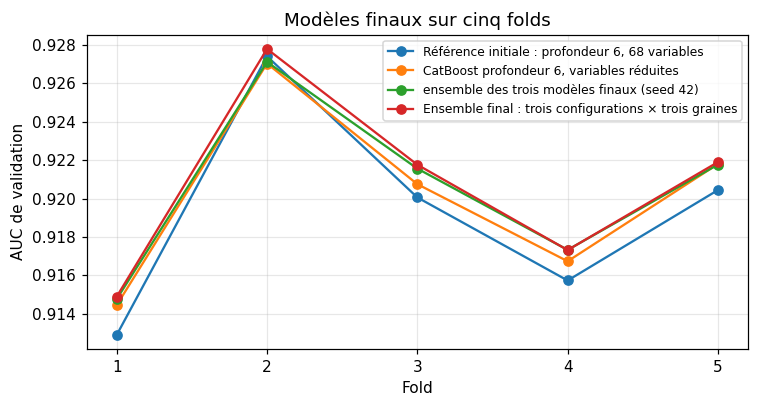

In [9]:
cv_runs = load_runs(CV_DIR)
per_group = cv_runs.pivot(index='fold', columns='group', values='valid_auc')
display_named(per_group.agg(['mean', 'std']).T.sort_values('mean', ascending=False).round(6))

oof = {g: read_oof(CV_DIR, g) for g in [MODEL_DEPTH6_INITIAL] + [b + t for b in FINAL_MODEL_NAMES for t in SEED_TAGS.values()]}
reference = oof[MODEL_DEPTH6_INITIAL]
for name, frame in oof.items():
    require(frame['id'].equals(reference['id']) and frame['fold'].equals(reference['fold']), f'Prédictions OOF non alignées : {name}')
blend_seed42 = np.mean([oof[b]['prob'] for b in FINAL_MODEL_NAMES], axis=0)
multiseed_ensemble = np.mean([np.mean([oof[b + t]['prob'] for t in SEED_TAGS.values()], axis=0) for b in FINAL_MODEL_NAMES], axis=0)
candidates = {
    'Référence initiale : profondeur 6, 68 variables': reference['prob'],
    'CatBoost profondeur 6, variables réduites': oof[MODEL_DEPTH6_REDUCED]['prob'],
    'ensemble des trois modèles finaux (seed 42)': blend_seed42,
    'Ensemble final : trois configurations × trois graines': multiseed_ensemble,
}
base_folds = fold_auc(reference, reference['prob'])
fold_table = pd.DataFrame({name: fold_auc(reference, prob) for name, prob in candidates.items()})
summary = pd.DataFrame({'AUC sur cinq folds': fold_table.mean(), 'Écart à la référence initiale': fold_table.sub(base_folds, axis=0).mean(),
                        'Folds améliorés': fold_table.sub(base_folds, axis=0).gt(0).sum()})
display_named(summary.round(6))

fig, ax = plt.subplots(figsize=(7, 3.8))
for name in fold_table.columns:
    ax.plot(fold_table.index, fold_table[name], marker='o', label=name)
ax.set_xticks(range(1, 6))
ax.set_xlabel('Fold')
ax.set_ylabel('AUC de validation')
ax.set_title('Modèles finaux sur cinq folds')
ax.legend(fontsize=8)
plt.tight_layout()
plt.show()

Les variables de la deuxième série apportent 0.0006 à 0.0009 selon le modèle. La moyenne des trois modèles donne 0.92051, et **0.92073** avec trois graines chacun, soit 0.0014 de plus que la référence, sur les 5 plis.

## 2. Courbe d'apprentissage

Un modèle de pli s'entraîne sur 84 000 lignes, soit 80 % des données. Est-ce que réentraîner sur les 105 000 lignes vaut la peine ? Pour en avoir une idée, on entraîne le modèle « profondeur 6, jeu réduit » sur 67 200 puis sur 84 000 lignes, avec les mêmes lignes de validation. Passer de 67 200 à 84 000, c'est 25 % de données en plus, comme passer de 84 000 à 105 000.

In [10]:
EXPERIMENT_ID = 'full_refit'
FOLDS = [1, 2, 3, 4, 5]
RUN_ONLY = None
INNER_STOP_FRACTION = 0.15
MAX_ITERATIONS = 10000
OD_WAIT = 300
OUTPUT_DIR = ARTIFACTS / '04_final_model' / EXPERIMENT_ID

GPU_BASE = dict(
    loss_function='Logloss', nan_mode='Min', random_seed=SEED,
    task_type='GPU', devices='0', thread_count=4,
    allow_writing_files=False, verbose=False,
)
INITIAL_FEATURE_BLOCKS = ['dti', 'ltv', 'income', 'missing', 'freq']
CORE_FEATURE_BLOCKS = ['dti', 'ltv', 'income', 'missing']
FAST_SCREEN_PARAMS = dict(depth=8, learning_rate=0.05, l2_leaf_reg=3,
            bootstrap_type='Bernoulli', subsample=0.8, early_stop=False, iterations=1600)
CATBOOST_DEPTH8_PARAMS = dict(depth=8, learning_rate=0.03, l2_leaf_reg=10, bootstrap_type='Bernoulli', subsample=0.8)
CATBOOST_DEPTH6_PARAMS = dict(depth=6, learning_rate=0.03, l2_leaf_reg=10, bootstrap_type='Bernoulli', subsample=0.8)
LTV_DETAIL_BLOCKS = ['precision', 'thresholds', 'implied', 'term']
ENRICHED_FEATURE_BLOCKS = CORE_FEATURE_BLOCKS + LTV_DETAIL_BLOCKS                      # Meilleur jeu de variables du notebook 02 (72 colonnes)
REDUCED_FEATURE_BLOCKS = CORE_FEATURE_BLOCKS + ['precision', 'thresholds']  # Deux blocs de la deuxième série utiles isolément (68 colonnes)
GROUPS = {
    MODEL_DEPTH6_INITIAL: dict(params=CATBOOST_DEPTH6_PARAMS, blocks=INITIAL_FEATURE_BLOCKS),   # Toutes les variables de la première série ; référence comparable (score public 0.92073)
    MODEL_DEPTH6_ENRICHED: dict(params=CATBOOST_DEPTH6_PARAMS, blocks=ENRICHED_FEATURE_BLOCKS),
    MODEL_DEPTH8_ENRICHED: dict(params=CATBOOST_DEPTH8_PARAMS, blocks=ENRICHED_FEATURE_BLOCKS),
    MODEL_DEPTH6_REDUCED: dict(params=CATBOOST_DEPTH6_PARAMS, blocks=REDUCED_FEATURE_BLOCKS),
}
BASELINE = MODEL_DEPTH6_INITIAL
CATBOOST_DIR = ARTIFACTS / '04_final_model' / 'cv_models'   # Résultats des cinq folds de la section 1
FINAL_MODEL_NAMES = [MODEL_DEPTH6_ENRICHED, MODEL_DEPTH8_ENRICHED, MODEL_DEPTH6_REDUCED]
SEED_SUFFIXES = {42: '', 2027: '_s2027', 31415: '_s31415'}
LEARNING_CURVE_MODEL = MODEL_DEPTH6_REDUCED       # Courbe d’apprentissage : meilleur groupe individuel sur cinq folds
LEARNING_CURVE_FRACTION = 0.8              # 80 % du train externe (67 200 lignes) contre 100 % (84 000 lignes)
FULL_ROUNDS_SCALE = 105000 / 84000   # Itérations complètes = moyenne des cinq réentraînements × ratio des effectifs (même règle que b/0.85)
RUN_LEARNING_CURVE = TRAIN['learning_curve']
RUN_FULL_REFIT = TRAIN['full_refit']
if RUN_ONLY is not None:
    unknown = set(RUN_ONLY) - set(GROUPS)
    if unknown:
        raise ValueError(f'Groupes inconnus dans RUN_ONLY : {sorted(unknown)}')

In [11]:
if TRAIN['learning_curve'] or TRAIN['full_refit']:
    ensure_catboost()
    ensure_gpu()
    fixed_config(OUTPUT_DIR, {
        'purpose': PURPOSE_FULL_REFIT,
        'seed': SEED, 'inner_stop_fraction': INNER_STOP_FRACTION,
        'max_iterations': MAX_ITERATIONS, 'od_wait': OD_WAIT,
        'lc_group': LEARNING_CURVE_MODEL, 'lc_fraction': LEARNING_CURVE_FRACTION, 'full_rounds_scale': FULL_ROUNDS_SCALE,
        'gpu_base': {k: v for k, v in GPU_BASE.items() if k != 'thread_count'},
        'data_hashes': DATA_HASHES,
    })


    def model_params(spec, iterations, seed):
        params = {k: v for k, v in spec.items() if k not in {'early_stop', 'iterations'}}
        return dict(GPU_BASE, **params, iterations=iterations, random_seed=seed)


    def early_stop_refit(spec, train, cats, idx, seed):
        """Protocole identique à 04 : réserver 15 % de idx pour l’arrêt anticipé, puis réentraîner sur tout idx pendant b/0.85 itérations."""
        inner_fit, inner_stop = train_test_split(idx, test_size=INNER_STOP_FRACTION,
                                                 random_state=SEED, stratify=y.iloc[idx])
        probe = catboost.CatBoostClassifier(**model_params(spec, MAX_ITERATIONS, seed),
                                            eval_metric='Logloss', od_type='Iter',
                                            od_wait=OD_WAIT, use_best_model=True)
        probe.fit(train.iloc[inner_fit], y.iloc[inner_fit], cat_features=cats,
                  eval_set=(train.iloc[inner_stop], y.iloc[inner_stop]))
        best = int(probe.get_best_iteration()) + 1
        rounds = int(round(best / (1 - INNER_STOP_FRACTION)))
        del probe
        gc.collect()
        model = catboost.CatBoostClassifier(**model_params(spec, rounds, seed), use_best_model=False)
        model.fit(train.iloc[idx], y.iloc[idx], cat_features=cats)
        require(int(model.tree_count_) == rounds, 'Nombre d’itérations de réentraînement incorrect')
        return model, best, rounds
else:
    print("Bloc désactivé (TRAIN['learning_curve'] or TRAIN['full_refit'] = False) ; affichage des résultats enregistrés dans artifacts/.")

Bloc désactivé (TRAIN['learning_curve'] or TRAIN['full_refit'] = False) ; affichage des résultats enregistrés dans artifacts/.


In [12]:
if TRAIN['learning_curve']:
    ensure_catboost()
    ensure_gpu()
    if RUN_LEARNING_CURVE:
        lc_spec = GROUPS[LEARNING_CURVE_MODEL]
        lc_train, _, lc_cats = variant_frames(lc_spec['blocks'])
        for fold in [1, 2, 3, 4, 5]:
            fit_idx = np.flatnonzero(fold_assignment != fold)
            valid_idx = np.flatnonzero(fold_assignment == fold)
            sub_idx, _ = train_test_split(fit_idx, train_size=LEARNING_CURVE_FRACTION, random_state=SEED + fold,
                                          stratify=y.iloc[fit_idx])
            for name, idx in [(LEARNING_CURVE_SUBSET, np.sort(sub_idx)), (LEARNING_CURVE_FULL, fit_idx)]:
                path = OUTPUT_DIR / f'{name}__fold{fold}.json'
                if path.is_file():
                    saved = json.loads(path.read_text(encoding='utf-8'))
                    print(f'{name} fold {fold}: terminé, AUC={saved["valid_auc"]:.6f}, ignoré')
                    continue
                started = time.perf_counter()
                model, best, rounds = early_stop_refit(lc_spec['params'], lc_train, lc_cats, idx, SEED)
                probability = checked_probabilities(model, lc_train.iloc[valid_idx])
                result = {'name': name, 'fold': fold, 'group': LEARNING_CURVE_MODEL, 'train_rows': int(len(idx)),
                          'inner_best_iteration': best, 'refit_rounds': rounds,
                          'valid_auc': roc_auc_score(y.iloc[valid_idx], probability),
                          'seconds': time.perf_counter() - started, 'gpu_name': GPU_NAME,
                          'finished_at_utc': datetime.now(timezone.utc).isoformat()}
                write_json(path, result)
                print(f'{name} fold {fold}: {len(idx):,} lignes  AUC={result["valid_auc"]:.6f}  '
                      f'itérations={rounds}  {result["seconds"]/60:.1f} min', flush=True)
                del model
                gc.collect()

    lc = pd.DataFrame([json.loads(p.read_text(encoding='utf-8')) for p in OUTPUT_DIR.glob(LEARNING_CURVE_RUN_PATTERN)])
    if not lc.empty:
        curve = lc.pivot(index='fold', columns='name', values='valid_auc')
        if {LEARNING_CURVE_SUBSET, LEARNING_CURVE_FULL} <= set(curve.columns):
            curve['gain_84k_vs_67k'] = curve[LEARNING_CURVE_FULL] - curve[LEARNING_CURVE_SUBSET]
        reference = {k: json.loads((CATBOOST_DIR / f'{LEARNING_CURVE_MODEL}__fold{k}.json').read_text(encoding='utf-8'))['valid_auc']
                     for k in curve.index}
        curve[REDUCED_MODEL_CV_AUC] = pd.Series(reference)
        display_named(curve.round(6))
        if 'gain_84k_vs_67k' in curve:
            done = curve['gain_84k_vs_67k'].dropna()
            print(f'Données ×1,25 (67k → 84k) : gain moyen d’AUC {done.mean():+.6f}, {int((done > 0).sum())}/{len(done)} folds en progrès.'
                  f' Le réentraînement complet (84k → 105k) augmente aussi les données de ×1,25 ; un gain comparable reste une hypothèse.')
else:
    print("Bloc désactivé (TRAIN['learning_curve'] = False) ; affichage des résultats enregistrés dans artifacts/.")

Bloc désactivé (TRAIN['learning_curve'] = False) ; affichage des résultats enregistrés dans artifacts/.


name,Apprentissage sur 84 000 lignes,Apprentissage sur 67 200 lignes,gain_84k_vs_67k
fold,,,
1,0.914297,0.912847,0.001450
2,0.927419,0.926396,0.001023
3,0.920750,0.919943,0.000807
4,0.916294,0.914993,0.001301
5,0.921569,0.920128,0.001441


Données ×1.25 (67 200 → 84 000 lignes) : gain AUC moyen +0.00120, 5/5 folds positifs


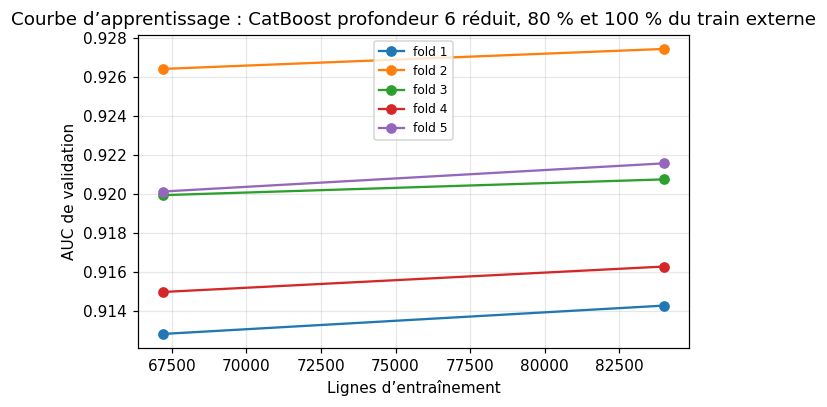

In [13]:
lc = load_runs(FULL_DIR, LEARNING_CURVE_RUN_PATTERN)
curve = lc.pivot(index='fold', columns='name', values='valid_auc')
curve['gain_84k_vs_67k'] = curve[LEARNING_CURVE_FULL] - curve[LEARNING_CURVE_SUBSET]
display_named(curve.round(6))
print(f"Données ×1.25 (67 200 → 84 000 lignes) : gain AUC moyen {curve['gain_84k_vs_67k'].mean():+.5f}, "
      f"{int((curve['gain_84k_vs_67k'] > 0).sum())}/5 folds positifs")

fig, ax = plt.subplots(figsize=(6, 3.8))
for fold, row in curve.iterrows():
    ax.plot([67200, 84000], [row[LEARNING_CURVE_SUBSET], row[LEARNING_CURVE_FULL]], marker='o', label=f'fold {fold}')
ax.set_xlabel('Lignes d’entraînement')
ax.set_ylabel('AUC de validation')
ax.set_title('Courbe d’apprentissage : CatBoost profondeur 6 réduit, 80 % et 100 % du train externe')
ax.legend(fontsize=8)
plt.tight_layout()
plt.show()

25 % de données en plus font gagner **0.0012 d'AUC, sur les 5 plis**. On réentraîne donc tout sur les 105 000 lignes, sans pouvoir mesurer directement ce que cela donne puisqu'il ne reste plus de lignes pour valider.

## 3. Réentraînement complet et fichiers de soumission

Les trois modèles × trois graines sont entraînés sur les 105 000 lignes. Le nombre d'itérations est la moyenne observée sur les cinq plis multipliée par 1.25, par analogie avec la règle `b / 0.85`. Les deux fichiers de soumission sont recalculés et comparés aux fichiers sauvegardés.

In [14]:
if TRAIN['full_refit']:
    ensure_catboost()
    ensure_gpu()
    def group_rounds(group):
        rounds = [json.loads((CATBOOST_DIR / f'{group}__fold{k}.json').read_text(encoding='utf-8'))['refit_rounds']
                  for k in range(1, 6)]
        return float(np.mean(rounds))


    if RUN_FULL_REFIT:
        for base in FINAL_MODEL_NAMES:
            spec = GROUPS[base]
            train, test, cats = variant_frames(spec['blocks'])
            for seed, suffix in SEED_SUFFIXES.items():
                name = f'FULL_{base}_seed{seed}'
                path = OUTPUT_DIR / f'{name}.json'
                if path.is_file():
                    print(f'{name}: terminé, ignoré')
                    continue
                rounds = int(round(group_rounds(base + suffix) * FULL_ROUNDS_SCALE))
                started = time.perf_counter()
                model = catboost.CatBoostClassifier(**model_params(spec['params'], rounds, seed),
                                                    use_best_model=False)
                model.fit(train, y, cat_features=cats)
                require(int(model.tree_count_) == rounds, 'Nombre d’itérations incorrect pour le modèle complet')
                probability = checked_probabilities(model, test)
                pd.DataFrame({'id': test_ids.to_numpy(), 'accepted': probability}).to_csv(
                    OUTPUT_DIR / f'{name}__test.csv', index=False, float_format='%.12f')
                write_json(path, {'name': name, 'base': base, 'seed': seed, 'train_rows': len(train),
                                  'rounds': rounds, 'seconds': time.perf_counter() - started,
                                  'gpu_name': GPU_NAME,
                                  'finished_at_utc': datetime.now(timezone.utc).isoformat()})
                print(f'{name}: {rounds} itérations  {(time.perf_counter() - started)/60:.1f} min', flush=True)
                del model
                gc.collect()

    def fold_average_multiseed_ensemble():
        per_base = []
        for base in FINAL_MODEL_NAMES:
            tests = [pd.read_csv(CATBOOST_DIR / f'{base}{s}__fold{k}__test.csv', dtype={'id': str})
                     for s in SEED_SUFFIXES.values() for k in range(1, 6)]
            for t in tests:
                require(t['id'].equals(sample_submission['id']), 'Ordre des ID test incohérent entre modèles de folds')
            per_base.append(np.mean([t['accepted'].to_numpy() for t in tests], axis=0))
        return np.mean(per_base, axis=0)


    full_paths = {(b, s): OUTPUT_DIR / f'FULL_{b}_seed{s}__test.csv' for b in FINAL_MODEL_NAMES for s in SEED_SUFFIXES}
    missing = [p.name for p in full_paths.values() if not p.is_file()]
    if missing:
        print(f'Modèles complets manquants : {len(missing)} (exemple : {missing[0]}). Relancer cette cellule une fois les modèles terminés.')
    else:
        per_base = []
        for base in FINAL_MODEL_NAMES:
            frames = [pd.read_csv(full_paths[(base, s)], dtype={'id': str}) for s in SEED_SUFFIXES]
            for f in frames:
                require(f['id'].equals(sample_submission['id']), 'Ordre des ID test incohérent entre modèles complets')
            per_base.append(np.mean([f['accepted'].to_numpy() for f in frames], axis=0))
        full = np.mean(per_base, axis=0)
        fold_avg = fold_average_multiseed_ensemble()
        print(f'Corrélation test : ensemble complet / moyenne des folds l’ensemble multigraines : {np.corrcoef(full, fold_avg)[0, 1]:.5f}')
        for name, probability in [(ENSEMBLE_FULL_MULTISEED, full), ('hybrid_50_50', 0.5 * full + 0.5 * fold_avg)]:
            require(np.isfinite(probability).all() and len(probability) == 45000, f'{name} : probabilités invalides')
            path = OUTPUT_DIR / f'submission_{name}.csv'
            pd.DataFrame({'id': sample_submission['id'], 'accepted': probability}).to_csv(
                path, index=False, float_format='%.12f')
            print('Fichier écrit :', path.name)
        if 'curve' in globals() and 'gain_84k_vs_67k' in curve and curve['gain_84k_vs_67k'].notna().sum() == 5:
            gain = curve['gain_84k_vs_67k']
            if gain.mean() >= 0.0005 and (gain > 0).sum() >= 4:
                advice = 'La courbe soutient le réentraînement complet. Choix final documenté : submission_full_Bseeds.csv (score public 0.92301) ; hybrid et l’ensemble multigraines restent des références.'
            elif gain.mean() >= 0.0002:
                advice = 'Gain limité sur la courbe d’apprentissage. Choix final documenté : submission_full_Bseeds.csv (score public 0.92301) ; hybrid et l’ensemble multigraines restent des références.'
            else:
                advice = 'La courbe ne montre pas de gain lié au volume. Choix final documenté : submission_full_Bseeds.csv (score public 0.92301), retenu après comparaison des soumissions ; ce diagnostic seul ne le justifie pas.'
            print('Bilan : ' + advice)
else:
    print("Bloc désactivé (TRAIN['full_refit'] = False) ; affichage des résultats enregistrés dans artifacts/.")

Bloc désactivé (TRAIN['full_refit'] = False) ; affichage des résultats enregistrés dans artifacts/.


In [15]:
full_runs = pd.DataFrame([json.loads(p.read_text(encoding='utf-8')) for p in sorted(FULL_DIR.glob('FULL_*.json'))])
display_named(full_runs[['name', 'base', 'seed', 'train_rows', 'rounds']].sort_values(['base', 'seed']))
full_pred = np.mean([mean_test([FULL_DIR / f'FULL_{b}_seed{s}__test.csv' for s in SEED_TAGS]) for b in FINAL_MODEL_NAMES], axis=0)
fold_pred = np.mean([mean_test([CV_DIR / f'{b}{t}__fold{k}__test.csv' for t in SEED_TAGS.values() for k in range(1, 6)])
                     for b in FINAL_MODEL_NAMES], axis=0)
checks = []
for label, path, expected in [
    ('Soumission finale l’ensemble complet multigraines', FULL_DIR / FULL_ENSEMBLE_SUBMISSION, full_pred),
    ('Alternative hybrid_50_50', FULL_DIR / 'submission_hybrid_50_50.csv', 0.5 * full_pred + 0.5 * fold_pred),
]:
    saved = pd.read_csv(path, dtype={'id': str})
    require(saved['id'].equals(sample_submission['id']), f'Ordre des ID différent du modèle de soumission : {path.name}')
    checks.append({'Fichier': label, 'Écart maximal au recalcul': float(np.abs(saved['accepted'].to_numpy() - expected).max())})
display_named(pd.DataFrame(checks))
print(f'Corrélation des prédictions test, modèles complets / moyenne des folds : {np.corrcoef(full_pred, fold_pred)[0, 1]:.5f}')

,name,base,seed,train_rows,rounds
2,FULL_CatBoost profondeur 6 · variables enrichi...,CatBoost profondeur 6 · variables enrichies,42,105000,6374
0,FULL_CatBoost profondeur 6 · variables enrichi...,CatBoost profondeur 6 · variables enrichies,2027,105000,6560
1,FULL_CatBoost profondeur 6 · variables enrichi...,CatBoost profondeur 6 · variables enrichies,31415,105000,6645
5,FULL_CatBoost profondeur 8 · variables enrichi...,CatBoost profondeur 8 · variables enrichies,42,105000,3734
3,FULL_CatBoost profondeur 8 · variables enrichi...,CatBoost profondeur 8 · variables enrichies,2027,105000,4066
4,FULL_CatBoost profondeur 8 · variables enrichi...,CatBoost profondeur 8 · variables enrichies,31415,105000,3730
8,FULL_CatBoost profondeur 6 · variables réduite...,CatBoost profondeur 6 · variables réduites,42,105000,5806
6,FULL_CatBoost profondeur 6 · variables réduite...,CatBoost profondeur 6 · variables réduites,2027,105000,5915
7,FULL_CatBoost profondeur 6 · variables réduite...,CatBoost profondeur 6 · variables réduites,31415,105000,5737


,Fichier,Écart maximal au recalcul
0,Soumission finale l’ensemble complet multigraines,4.446443e-13
1,Alternative hybrid_50_50,5.000445e-13


Corrélation des prédictions test, modèles complets / moyenne des folds : 0.99925


## 4. Soumissions et score public

Le score public porte sur environ 30 % du test (13 500 lignes). À 0.001 près, il dépend de ce tirage (voir le notebook 05). On choisit donc d'après la validation et la courbe d'apprentissage ; les scores publics ci-dessous vont dans le même sens.

In [16]:
public = pd.DataFrame([
    ('CatBoost profondeur 8 CPU, 56 features sources', 0.91604, 0.91857),
    ('CatBoost profondeur 8 GPU (mêmes paramètres)', 0.91498, 0.91764),
    ('CatBoost profondeur 6 + features de la série 1 (la référence initiale)', 0.91931, 0.92073),
    ('ensemble des trois modèles finaux (seed 42), moyenne des folds', 0.92051, 0.92190),
    ('Ensemble final : trois configurations × trois graines, moyenne des folds', 0.92073, 0.92197),
    ('hybrid : 50 % données complètes + 50 % moyenne des folds', np.nan, 0.92259),
    ('l’ensemble complet multigraines : 9 modèles sur les 105 000 lignes (FINAL)', np.nan, 0.92301),
], columns=['Soumission', 'AUC sur cinq folds', 'AUC publique'])
display_named(public)

,Soumission,AUC sur cinq folds,AUC publique
0,"CatBoost profondeur 8 CPU, 56 features sources",0.91604,0.91857
1,CatBoost profondeur 8 GPU (mêmes paramètres),0.91498,0.91764
2,CatBoost profondeur 6 + features de la série 1...,0.91931,0.92073
3,"ensemble des trois modèles finaux (seed 42), m...",0.92051,0.92190
4,Ensemble final : trois configurations × trois ...,0.92073,0.92197
5,hybrid : 50 % données complètes + 50 % moyenne...,NaN,0.92259
6,l’ensemble complet multigraines : 9 modèles su...,NaN,0.92301


**Soumission finale** : `submission_full_Bseeds.csv`, score public 0.92301. Le mélange à parts égales avec les modèles de plis, `submission_hybrid_50_50.csv`, fait 0.92259. Les deux sont copiés dans `submissions/`.